In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

df = pd.read_csv("nobel_prize_winners.csv")

print(df.shape)
df.head()

(950, 52)


,awardYear,category,categoryFullName,sortOrder,portion,prizeAmount,prizeAmountAdjusted,dateAwarded,prizeStatus,motivation,...,org_founded_country,org_founded_countryNow,org_founded_locationString,ind_or_org,residence_1,residence_2,affiliation_1,affiliation_2,affiliation_3,affiliation_4
0,2001,Economic Sciences,The Sveriges Riksbank Prize in Economic Scienc...,2,1/3,10000000,12295082,2001-10-10,received,for their analyses of markets with asymmetric ...,...,NaN,NaN,NaN,Individual,NaN,NaN,"Stanford University, Stanford, CA, USA",NaN,NaN,NaN
1,1975,Physics,The Nobel Prize in Physics,1,1/3,630000,3404179,1975-10-17,received,for the discovery of the connection between co...,...,NaN,NaN,NaN,Individual,NaN,NaN,"Niels Bohr Institute, Copenhagen, Denmark",NaN,NaN,NaN
2,2004,Chemistry,The Nobel Prize in Chemistry,1,1/3,10000000,11762861,2004-10-06,received,for the discovery of ubiquitin-mediated protei...,...,NaN,NaN,NaN,Individual,NaN,NaN,"Technion - Israel Institute of Technology, Hai...",NaN,NaN,NaN
3,1982,Chemistry,The Nobel Prize in Chemistry,1,1,1150000,3102518,1982-10-18,received,for his development of crystallographic electr...,...,NaN,NaN,NaN,Individual,NaN,NaN,"MRC Laboratory of Molecular Biology, Cambridge...",NaN,NaN,NaN
4,1979,Physics,The Nobel Prize in Physics,2,1/3,800000,2988048,1979-10-15,received,for their contributions to the theory of the u...,...,NaN,NaN,NaN,Individual,NaN,NaN,"International Centre for Theoretical Physics, ...","Imperial College, London, United Kingdom",NaN,NaN


In [ ]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
awardYear,950.0,NaN,NaN,NaN,1971.207368,33.586969,1901.0,1947.0,1977.0,2000.0,2019.0
category,950,6,Physiology or Medicine,219,NaN,NaN,NaN,NaN,NaN,NaN,NaN
categoryFullName,950,6,The Nobel Prize in Physiology or Medicine,219,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sortOrder,950.0,NaN,NaN,NaN,1.483158,0.688021,1.0,1.0,1.0,2.0,3.0
portion,950,4,1,350,NaN,NaN,NaN,NaN,NaN,NaN,NaN
prizeAmount,950.0,NaN,NaN,NaN,3460596.127368,4014529.562871,114935.0,170332.0,700000.0,8000000.0,10000000.0
prizeAmountAdjusted,950.0,NaN,NaN,NaN,6145680.669474,3276873.89282,2377268.0,3052326.0,4997406.0,9044276.0,12295082.0
dateAwarded,533,257,1988-10-19,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
prizeStatus,950,3,received,947,NaN,NaN,NaN,NaN,NaN,NaN,NaN
motivation,950,664,for the development of lithium-ion batteries,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
missing = df.isnull().sum().to_frame("missing_count")


missing["missing_pct"] = (missing["missing_count"] / len(df) * 100).round(1)


missing[missing["missing_count"] > 0].sort_values("missing_count", ascending=False)


,missing_count,missing_pct
affiliation_4,949,99.9
residence_2,948,99.8
affiliation_3,948,99.8
penName,939,98.8
acronym,939,98.8
categoryTopMotivation,930,97.9
org_founded_city,928,97.7
org_founded_cityNow,928,97.7
org_founded_continent,926,97.5
org_founded_country,926,97.5


In [ ]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate IDs:", df["id"].duplicated().sum())

print()

print("Individual/Organization:")
print(df["ind_or_org"].value_counts())

print()

print("Gender:")
print(df["gender"].value_counts(dropna=False))

print()

print("Prize portion:", sorted(df["portion"].unique()))

print("Birth countries:", df["birth_country"].nunique())

Duplicate rows: 0
Duplicate IDs: 7

Individual/Organization:
ind_or_org
Individual      923
Organization     27
Name: count, dtype: int64

Gender:
gender
male      869
female     54
NaN        27
Name: count, dtype: int64

Prize portion: ['1', '1/2', '1/3', '1/4']
Birth countries: 95


In [ ]:
duplicates = df[df.duplicated("id", keep=False)][
    ["id", "fullName", "awardYear", "category", "portion"]
]

duplicates

,id,fullName,awardYear,category,portion
264,222,Frederick Sanger,1958,Chemistry,1
391,482,NaN,1917,Peace,1
457,66,John Bardeen,1956,Physics,1/3
544,217,Linus Carl Pauling,1962,Peace,1
566,6,"Marie Curie, née Sklodowska",1903,Physics,1/4
634,515,NaN,1954,Peace,1
943,222,Frederick Sanger,1980,Chemistry,1/4
944,482,NaN,1944,Peace,1
945,66,John Bardeen,1972,Physics,1/3
946,217,Linus Carl Pauling,1954,Chemistry,1


In [ ]:

print(df["category"].value_counts())


print(df["gender"].value_counts())


df["decade"] = (df["awardYear"] // 10) * 10
print(df["decade"].value_counts().sort_index())

category
Physiology or Medicine    219
Physics                   213
Chemistry                 184
Peace                     134
Literature                116
Economic Sciences          84
Name: count, dtype: int64
gender
male      869
female     54
Name: count, dtype: int64
decade
1900     57
1910     40
1920     54
1930     56
1940     43
1950     72
1960     79
1970    104
1980     97
1990    104
2000    123
2010    121
Name: count, dtype: int64


In [ ]:

pd.crosstab(df["category"], df["gender"])

gender,female,male
category,,
Chemistry,5,179
Economic Sciences,2,82
Literature,15,101
Peace,17,90
Physics,3,210
Physiology or Medicine,12,207


In [ ]:


df.groupby("category")["prizeAmount"].mean().sort_values(ascending=False)

category
Economic Sciences         6.105845e+06
Chemistry                 3.629279e+06
Physics                   3.407939e+06
Peace                     3.124879e+06
Physiology or Medicine    3.072973e+06
Literature                2.493811e+06
Name: prizeAmount, dtype: float64

### Insight 1 — What age are laureates when they win, and does it differ by category?

**Question:** What does the age distribution of laureates look like, and is it similar across categories?

**Analysis:** Compute `age` for individuals, plot the overall distribution, then compare categories with
a box plot .

C:\Users\$ H i K o\AppData\Local\Temp\ipykernel_25348\4052494970.py:4: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["birth_year"] = pd.to_datetime(df["birth_date"], errors="coerce").dt.year


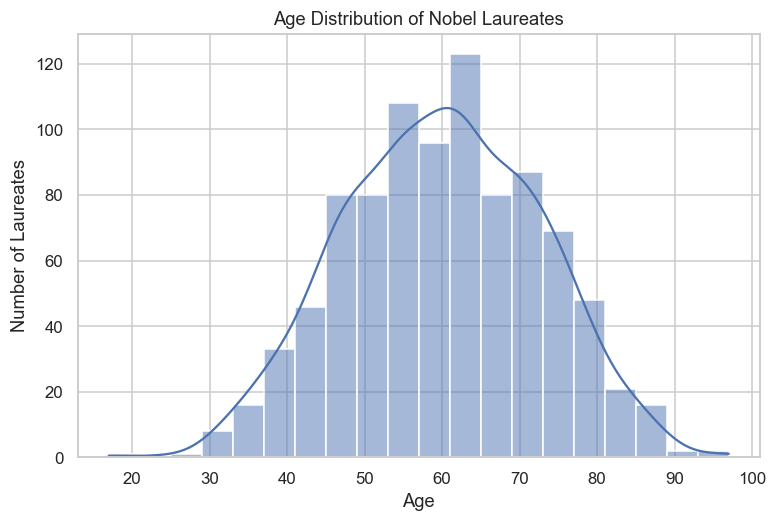

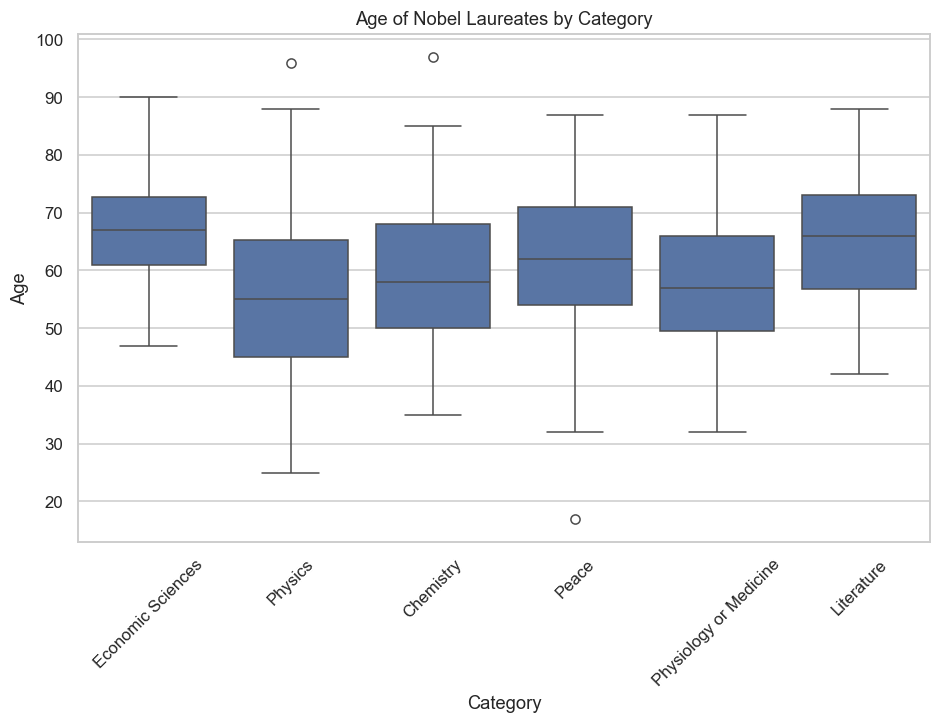

                             mean  median   min   max
category                                             
Chemistry               58.879781    58.0  35.0  97.0
Economic Sciences       66.865854    67.0  47.0  90.0
Literature              64.689655    66.0  42.0  88.0
Peace                   61.238095    62.0  17.0  87.0
Physics                 56.259434    55.0  25.0  96.0
Physiology or Medicine  58.360731    57.0  32.0  87.0


In [ ]:

df["birth_year"] = pd.to_datetime(df["birth_date"], errors="coerce").dt.year


df["age"] = df["awardYear"] - df["birth_year"]


individuals = df[df["ind_or_org"] == "Individual"]


plt.figure(figsize=(8, 5))
sns.histplot(individuals["age"].dropna(), bins=20, kde=True)
plt.xlabel("Age")
plt.ylabel("Number of Laureates")
plt.title("Age Distribution of Nobel Laureates")
plt.show()


plt.figure(figsize=(10, 6))
sns.boxplot(data=individuals, x="category", y="age")
plt.xlabel("Category")
plt.ylabel("Age")
plt.title("Age of Nobel Laureates by Category")
plt.xticks(rotation=45)
plt.show()
print(individuals.groupby("category")["age"].agg(["mean", "median", "min", "max"]))

Finding

The typical age of Nobel laureates at the time of winning varies by category. Physics has the youngest median age (56 years), while Literature and Economics have the oldest median age (67 years). The mean age follows a similar pattern, ranging from 57.3 years in Physics to 66.9 years in Economics.

Interpretation

This shows that the age at which laureates receive the Nobel Prize differs across fields. Laureates in Physics tend to receive the prize at a younger age, while laureates in Literature and Economics tend to be older. The wide minimum–maximum ranges also show that Nobel Prizes can be awarded to people at very different stages of their careers.

### Insight 2 — Which countries have produced the most laureates, and is that dominance uniform?

**Question:** Which birth countries produced the most laureates overall, and does the same handful of
countries dominate every category?

**Analysis:** Rank countries by laureate count using the cleaned birth-country field, then check whether
the top countries' *category mix* looks similar or different.

birth_country
USA                274
United Kingdom      87
Germany             77
France              53
Sweden              29
Japan               27
Canada              20
Switzerland         19
the Netherlands     18
Russian Empire      17
Name: count, dtype: int64
category         Chemistry  Economic Sciences  Literature  Peace  Physics  \
birth_country                                                               
Canada                   4                  3           2      1        6   
France                   9                  4          11      9        8   
Germany                 23                  2           4      6       22   
Japan                    7                  0           3      1       11   
Russian Empire           3                  2           4      2        3   
Sweden                   4                  2           7      5        4   
Switzerland              3                  0           1      3        6   
USA                     54           

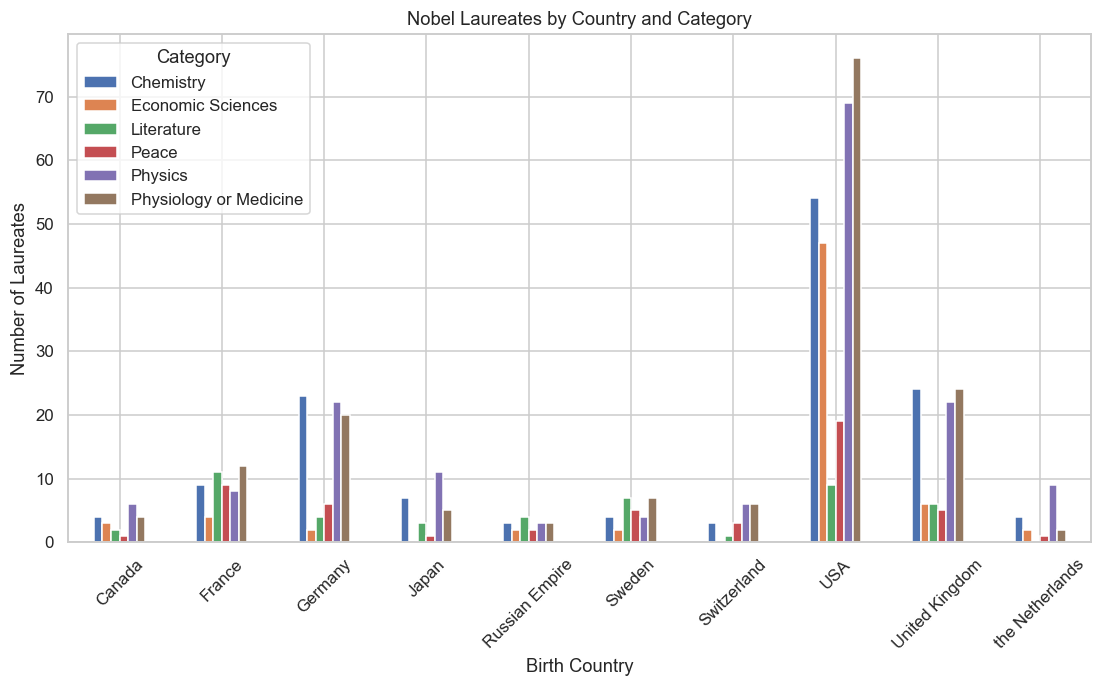

In [ ]:

country_counts = df["birth_country"].value_counts()


print(country_counts.head(10))


top_countries = country_counts.head(10).index


category_mix = pd.crosstab(
    df[df["birth_country"].isin(top_countries)]["birth_country"],
    df[df["birth_country"].isin(top_countries)]["category"]
)

print(category_mix)


category_mix.plot(kind="bar", figsize=(12, 6))

plt.xlabel("Birth Country")
plt.ylabel("Number of Laureates")
plt.title("Nobel Laureates by Country and Category")
plt.xticks(rotation=45)
plt.legend(title="Category")
plt.show()

Finding

The USA is the dominant birth country, with 274 laureates, far ahead of the United Kingdom (87) and Germany (77). The USA also has the highest number of laureates in most categories, particularly Physiology or Medicine (76) and Physics (69).

However, the dominance is not completely uniform across categories. For example, Germany has strong representation in Chemistry (23) and Physics (22), while France has relatively high numbers in Literature (11) and Physiology or Medicine (12).

Interpretation

This suggests that the USA has a strong overall dominance in Nobel laureates, but different countries have different strengths across fields. Therefore, the same countries do not dominate every Nobel category equally.

### Insight 3 — Has the geography of Nobel Prizes shifted across different historical periods?

**Question:** Did the leading countries change between the early 20th century and the modern era?

**Analysis:** Compare each top country's share of *all* laureates within three broad eras
(1901–1950, 1951–2000, 2001–2023) using a stacked bar chart, so the shifting composition is visible at a
glance.

birth_country  Canada  France  Germany  Japan  Russian Empire  Sweden  \
era                                                                     
1901–1950         0.8    10.5     11.2    0.4             2.7     4.7   
1951–2000         2.6     3.7      8.7    1.7             2.2     3.3   
2001–2023         2.6     3.9      3.5    7.8             0.0     0.9   

birth_country  Switzerland   USA  United Kingdom  the Netherlands  
era                                                                
1901–1950              3.1  14.7            10.5              3.1  
1951–2000              1.5  32.5             8.5              2.0  
2001–2023              1.7  37.2             9.1              0.4  


C:\Users\$ H i K o\AppData\Local\Temp\ipykernel_25348\2127031152.py:23: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  era_share = era_country.div(df.groupby("era").size(), axis=0) * 100


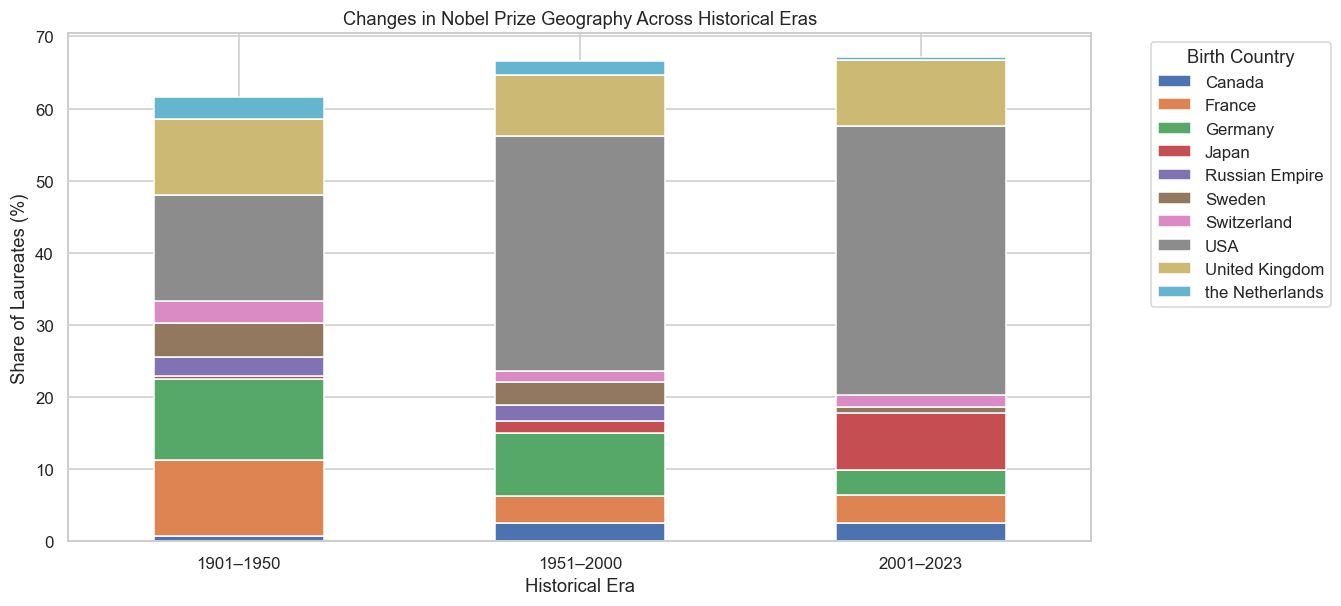

In [ ]:

df["era"] = pd.cut(
    df["awardYear"],
    bins=[1900, 1950, 2000, 2023],
    labels=["1901–1950", "1951–2000", "2001–2023"]
)


top_countries = df["birth_country"].value_counts().head(10).index


top_data = df[df["birth_country"].isin(top_countries)]


era_country = pd.crosstab(
    top_data["era"],
    top_data["birth_country"]
)


era_share = era_country.div(df.groupby("era").size(), axis=0) * 100

print(era_share.round(1))


era_share.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.xlabel("Historical Era")
plt.ylabel("Share of Laureates (%)")
plt.title("Changes in Nobel Prize Geography Across Historical Eras")
plt.xticks(rotation=0)
plt.legend(title="Birth Country", bbox_to_anchor=(1.05, 1))
plt.show()

### Finding

The geographical distribution of Nobel laureates changed significantly over time. The USA's share increased from 14.7% in 1901–1950 to 32.5% in 1951–2000, reaching 37.2% in 2001–2023. In contrast, Germany's share decreased from 11.2% to 3.5%, while France decreased from 10.5% to 3.9%. Japan became more prominent in the modern era, increasing from 0.4% in 1901–1950 to 7.8% in 2001–2023.

### Interpretation

These results show a clear shift in Nobel Prize geography over time. The USA became increasingly dominant, while several European countries became less represented. Japan also gained a stronger presence in the modern era. This suggests that the countries contributing the most Nobel laureates have changed across historical periods.


### Insight 4 — Unusual and exceptional cases

**Question:** Who are the extreme outliers in the age distribution, and what does the very shape of the
tails tell us?

**Analysis:** Pull the youngest and oldest laureates directly, and mark them on the age histogram

Youngest laureate:
fullName     Malala Yousafzai
age                      17.0
awardYear                2014
category                Peace
Name: 562, dtype: object

Oldest laureate:
fullName     John B. Goodenough
age                        97.0
awardYear                  2019
category              Chemistry
Name: 456, dtype: object


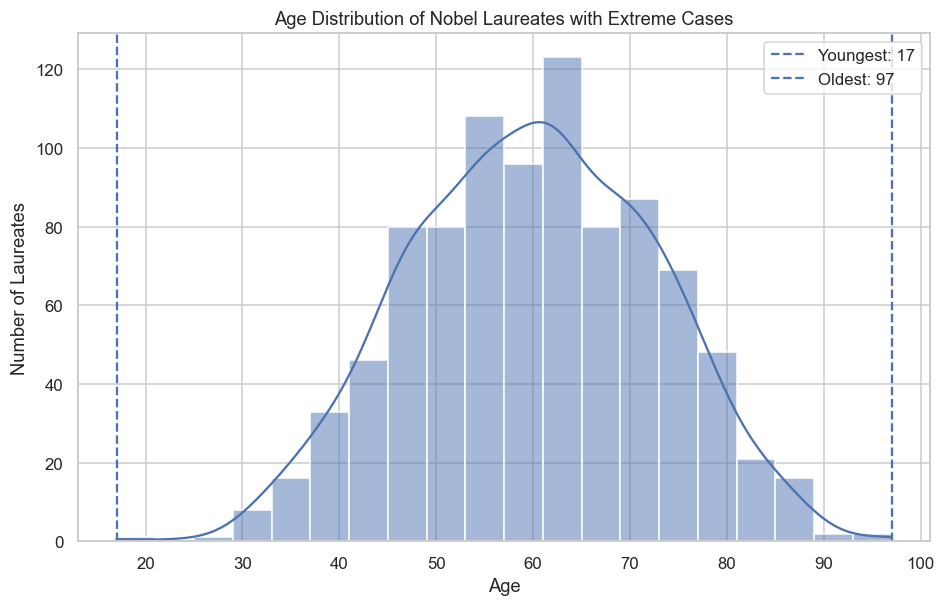

In [ ]:


youngest = individuals.loc[individuals["age"].idxmin()]
oldest = individuals.loc[individuals["age"].idxmax()]

print("Youngest laureate:")
print(youngest[["fullName", "age", "awardYear", "category"]])

print("\nOldest laureate:")
print(oldest[["fullName", "age", "awardYear", "category"]])
plt.figure(figsize=(10, 6))

sns.histplot(individuals["age"].dropna(), bins=20, kde=True)

plt.axvline(youngest["age"], linestyle="--", label=f'Youngest: {youngest["age"]:.0f}')
plt.axvline(oldest["age"], linestyle="--", label=f'Oldest: {oldest["age"]:.0f}')

plt.xlabel("Age")
plt.ylabel("Number of Laureates")
plt.title("Age Distribution of Nobel Laureates with Extreme Cases")
plt.legend()

plt.show()

### Finding

The age distribution contains two notable extreme cases. Malala Yousafzai was the youngest laureate, receiving the Nobel Peace Prize at age 17 in 2014. John B. Goodenough was the oldest laureate, receiving the Nobel Prize in Chemistry at age 97 in 2019. These cases appear at the extreme ends of the age distribution.

### Interpretation

The age distribution shows that Nobel Prizes can be awarded at very different ages. Most laureates are concentrated around middle and older adulthood, while the very young and very old laureates form the tails of the distribution. Malala Yousafzai represents an exceptional young case, whereas John B. Goodenough represents an exceptional old case. These extreme values demonstrate the wide range of ages at which Nobel recognition can occur.


### Insight 5 — Are there Nobel "families"?

**Question:** Do any laureates appear to share a surname with another laureate — and if so, are any of
these real family dynasties rather than coincidence?

**Analysis:** Extract a naive surname (last word of `fullname`) for individuals, exclude the dataset's
own repeat winners (same `id`, e.g. Marie Curie appearing twice under "Sklodowska"), and look at
which surnames appear more than once with genuinely different people.

In [ ]:

individuals = df[df["ind_or_org"] == "Individual"].copy()


individuals["surname"] = individuals["fullName"].str.split().str[-1]


family_table = (
    individuals.groupby("surname")
    .filter(lambda x: x["id"].nunique() > 1)
    [["surname", "fullName", "awardYear", "category", "id"]]
    .sort_values("surname")
)

family_table

,surname,fullName,awardYear,category,id
114,Anderson,Carl David Anderson,1936,Physics,43
690,Anderson,Philip Warren Anderson,1977,Physics,107
519,Bloch,Konrad Bloch,1964,Physiology or Medicine,378
241,Bloch,Felix Bloch,1952,Physics,58
1,Bohr,Aage Niels Bohr,1975,Physics,102
...,...,...,...,...,...
99,Williams,Elizabeth Williams,1976,Peace,535
109,Wilson,Charles Thomson Rees Wilson,1927,Physics,34
755,Wilson,Robert Woodrow Wilson,1978,Physics,112
934,Wilson,Thomas Woodrow Wilson,1919,Peace,483


### Finding

Several different Nobel laureates share the same surname. The analysis identified 99 laureate records with surnames shared by other individuals. Examples include Anderson, Bloch, Bohr, and Wilson, with some shared surnames appearing across different Nobel categories.

### Interpretation

Repeated surnames may indicate Nobel families, but a shared surname alone does not prove that the laureates are related. Some matches may simply be coincidences. Therefore, the repeated surnames are best treated as possible family connections that would require additional biographical information to confirm.


### Insight 6 — When did each country first appear in Nobel history, and is the map still expanding?

**Question:** Rather than looking at who has the most laureates, when did each country get its *first*
laureate — and is the Nobel Prize still "discovering" new countries in recent years?

**Analysis:** Find the minimum award year per birth country, and plot each country's first appearance
against time, colored by the category of that first prize.

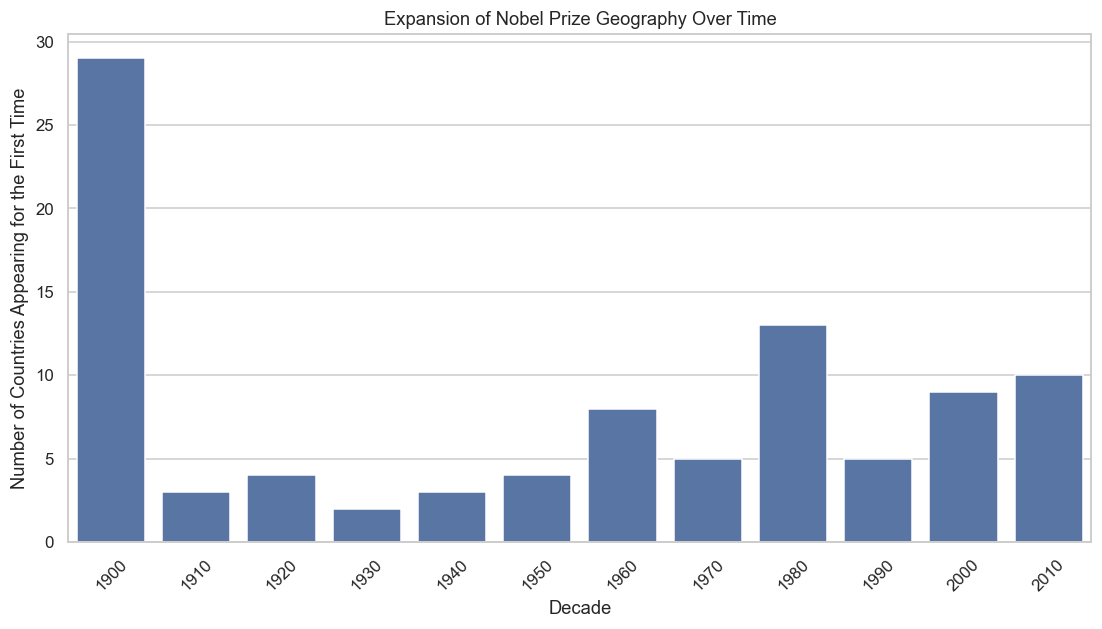

In [ ]:


first_appearance = (
    df.dropna(subset=["birth_country"])
      .sort_values("awardYear")
      .drop_duplicates("birth_country")
      [["birth_country", "awardYear"]]
)


first_appearance["decade"] = (
    first_appearance["awardYear"] // 10
) * 10

new_countries = (
    first_appearance["decade"]
    .value_counts()
    .sort_index()
)


plt.figure(figsize=(12, 6))

sns.barplot(
    x=new_countries.index,
    y=new_countries.values
)

plt.xlabel("Decade")
plt.ylabel("Number of Countries Appearing for the First Time")
plt.title("Expansion of Nobel Prize Geography Over Time")

plt.xticks(rotation=45)
plt.show()

Finding

The number of countries receiving their first Nobel Prize increased over time, showing that the geographical reach of the Nobel Prize expanded beyond the countries represented in its early years. However, the number of new countries appearing varies across decades, indicating that this expansion was not constant.

Interpretation

This suggests that the Nobel Prize gradually became more geographically diverse. While many countries appeared early in Nobel history, new countries continued to enter the Nobel map in later periods, showing that the geographical reach of the prizes has continued to expand.

### Insight 7 — Were any prizes awarded posthumously, despite the rule against it?

**Question:** The Nobel Foundation's statutes have (since 1974) generally disallowed posthumous awards —
does the data show any laureates who died in the same year they won, suggesting an edge case?

**Analysis:** Parse `death_date` and flag laureates whose death year is less than or equal to their award
year.

In [ ]:

df["death_year"] = pd.to_datetime(df["death_date"], errors="coerce").dt.year


posthumous = df[
    df["death_year"].notna() &
    (df["death_year"] <= df["awardYear"])
]


posthumous[
    ["fullName", "awardYear", "death_date", "category"]
]

,fullName,awardYear,death_date,category
151,Dag Hjalmar Agne Carl Hammarskjöld,1961,1961-09-18,Peace
220,Erik Axel Karlfeldt,1931,1931-04-08,Literature
704,Ralph M. Steinman,2011,2011-09-30,Physiology or Medicine
924,William Vickrey,1996,1996-10-11,Economic Sciences


Finding

Four Nobel laureates died in the same year they received their Nobel Prize:

Dag Hammarskjöld — Peace, 1961

Erik Axel Karlfeldt — Literature, 1931

Ralph M. Steinman — Physiology or Medicine, 2011

William Vickrey — Economic Sciences, 1996

All four died after the award year had begun, so these are same-year edge cases rather than clear cases of a prize being awarded after death.

Interpretation

These cases show that the dataset contains a few unusual situations where laureates died during the same year they received the prize. They should not automatically be considered violations of the posthumous-award rule, because the data only compares the year, not whether the person was alive on the exact award date.

### Insight 8 — How common is prize-sharing, and has it changed?

**Question:** How often is a Nobel Prize split between multiple laureates rather than given to one
person, and has that changed over time or by category?

**Analysis:** Use the `prize_share_frac` / `shared_prize` columns created during preprocessing. Compute
the share of shared awards per decade and per category.

Shared prizes by decade:
decade
1900     23
1910      8
1920     20
1930     23
1940     19
1950     42
1960     50
1970     77
1980     61
1990     76
2000    103
2010     98
Name: shared_prize, dtype: int64

Shared prizes by category:
category
Physiology or Medicine    180
Physics                   166
Chemistry                 121
Peace                      66
Economic Sciences          59
Literature                  8
Name: shared_prize, dtype: int64


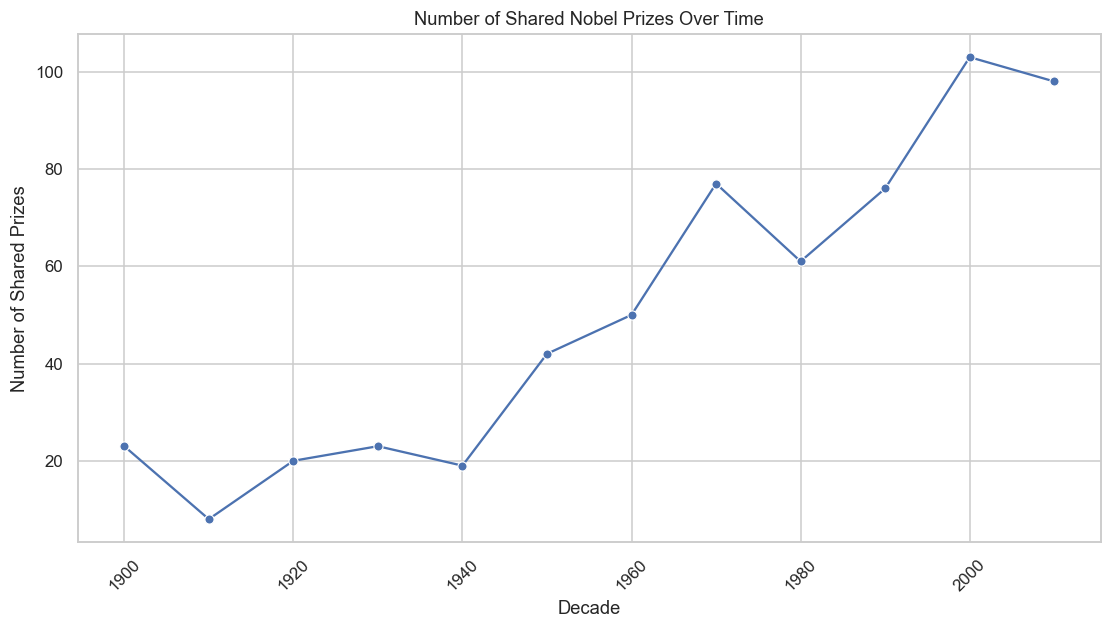

In [ ]:

df["shared_prize"] = df["portion"] != "1"

shared_by_decade = (
    df.groupby("decade")["shared_prize"]
      .sum()
)


shared_by_category = (
    df.groupby("category")["shared_prize"]
      .sum()
      .sort_values(ascending=False)
)

print("Shared prizes by decade:")
print(shared_by_decade)

print("\nShared prizes by category:")
print(shared_by_category)


plt.figure(figsize=(12, 6))

sns.lineplot(
    x=shared_by_decade.index,
    y=shared_by_decade.values,
    marker="o"
)

plt.xlabel("Decade")
plt.ylabel("Number of Shared Prizes")
plt.title("Number of Shared Nobel Prizes Over Time")
plt.xticks(rotation=45)

plt.show()

Finding

Prize-sharing became more common over time. The number of shared prizes increased from 23 in the 1900s to 103 in the 2000s, with 98 shared prizes in the 2010s. By category, Physiology or Medicine had the most shared prizes (180), followed by Physics (166) and Chemistry (121). Literature had the fewest, with only 8 shared prizes.

Interpretation

These results suggest that Nobel Prizes have increasingly been awarded jointly, especially in the scientific categories. The much higher numbers in Physiology or Medicine, Physics, and Chemistry may reflect the collaborative nature of scientific research, where important discoveries are often made by multiple researchers.

### Insight 9 — Is the Peace Prize structurally different from the other categories?

**Question:** The dataset includes 34 laureates classified as `Organization` rather than `Individual` —
are these spread across categories, or concentrated somewhere specific?

**Analysis:** Cross-tabulate `category` by `laureate_type`.

Individual vs Organization by Category:
ind_or_org              Individual  Organization
category                                        
Chemistry                      184             0
Economic Sciences               84             0
Literature                     116             0
Peace                          107            27
Physics                        213             0
Physiology or Medicine         219             0


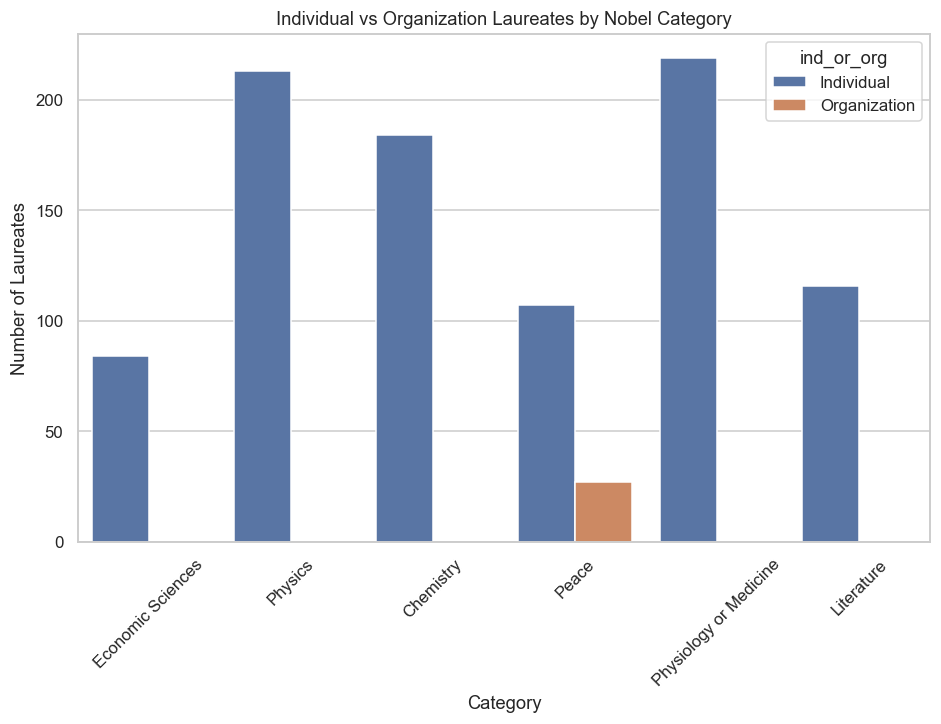

In [ ]:

category_type = pd.crosstab(
    df["category"],
    df["ind_or_org"]
)

print("Individual vs Organization by Category:")
print(category_type)
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x="category",
    hue="ind_or_org"
)

plt.xlabel("Category")
plt.ylabel("Number of Laureates")
plt.title("Individual vs Organization Laureates by Nobel Category")
plt.xticks(rotation=45)

plt.show()

Finding

Organizations are completely concentrated in the Peace Prize. The Peace category contains 107 Individuals and 27 Organizations, while all other Nobel categories contain only Individuals and no Organizations.

Interpretation

This shows that the Peace Prize is structurally different from the other Nobel categories because it can be awarded to organizations. The other categories in this dataset are awarded exclusively to individuals.




### Insight 10 — Does Gender Distribution Differ Across Nobel Categories?

***Question:*** Are the 27 laureates classified as Organization concentrated in one Nobel category or spread across several categories?

***Analysis:*** Cross-tabulate category by ind_or_org to compare the number of Individuals and Organizations in each Nobel category

Gender Distribution by Category:
gender                  female  male
category                            
Chemistry                    5   179
Economic Sciences            2    82
Literature                  15   101
Peace                       17    90
Physics                      3   210
Physiology or Medicine      12   207


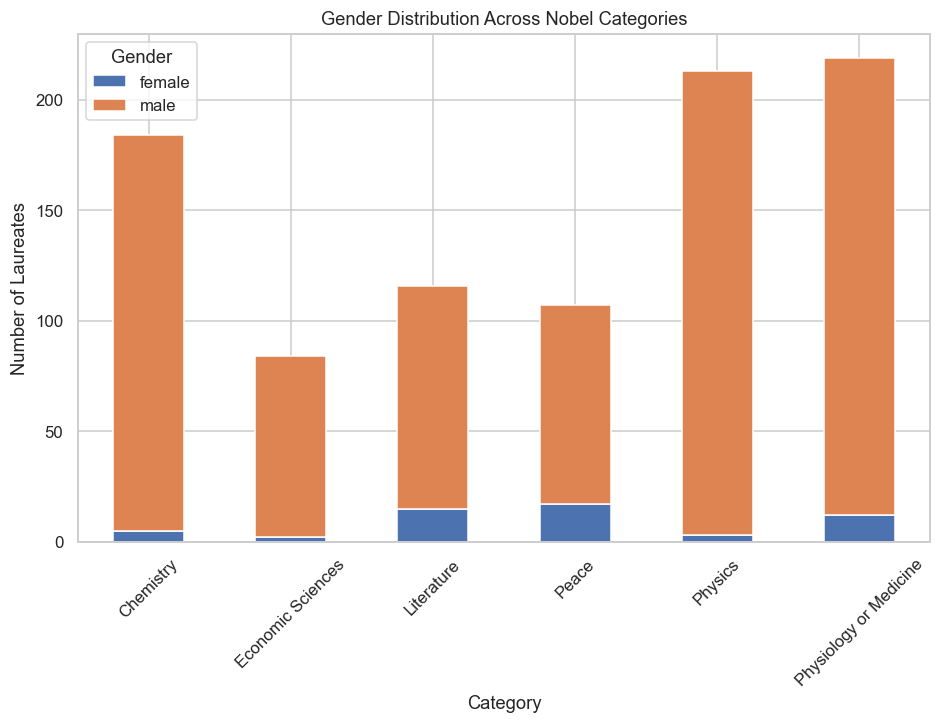

In [ ]:

gender_category = pd.crosstab(
    df["category"],
    df["gender"]
)

print("Gender Distribution by Category:")
print(gender_category)


gender_category.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.xlabel("Category")
plt.ylabel("Number of Laureates")
plt.title("Gender Distribution Across Nobel Categories")
plt.xticks(rotation=45)
plt.legend(title="Gender")

plt.show()

Finding

Male laureates greatly outnumber female laureates in every category. Peace has the highest number of female laureates (17), followed by Literature (15). In contrast, Physics has only 3 female laureates compared with 210 male laureates, while Chemistry has 5 female laureates compared with 179 male laureates.

Interpretation

This shows a strong gender imbalance across Nobel categories. Female representation is relatively higher in Peace and Literature, while the scientific categories, especially Physics and Chemistry, have much lower female representation.

### Insight 11 — How Has Nobel Prize Money Changed Over Time?

***Question:*** Has the financial value of the Nobel Prize changed throughout the history of the awards?

***Analysis:*** Compare the average prizeAmount across different award years or decades to identify changes in the monetary value of the Nobel Prize.

Average Prize Amount by Decade:
decade
1900    1.411214e+05
1910    1.404793e+05
1920    1.309524e+05
1930    1.631663e+05
1940    1.347229e+05
1950    1.898656e+05
1960    2.925580e+05
1970    6.006154e+05
1980    1.776856e+06
1990    6.810577e+06
2000    9.894309e+06
2010    8.719008e+06
Name: prizeAmount, dtype: float64


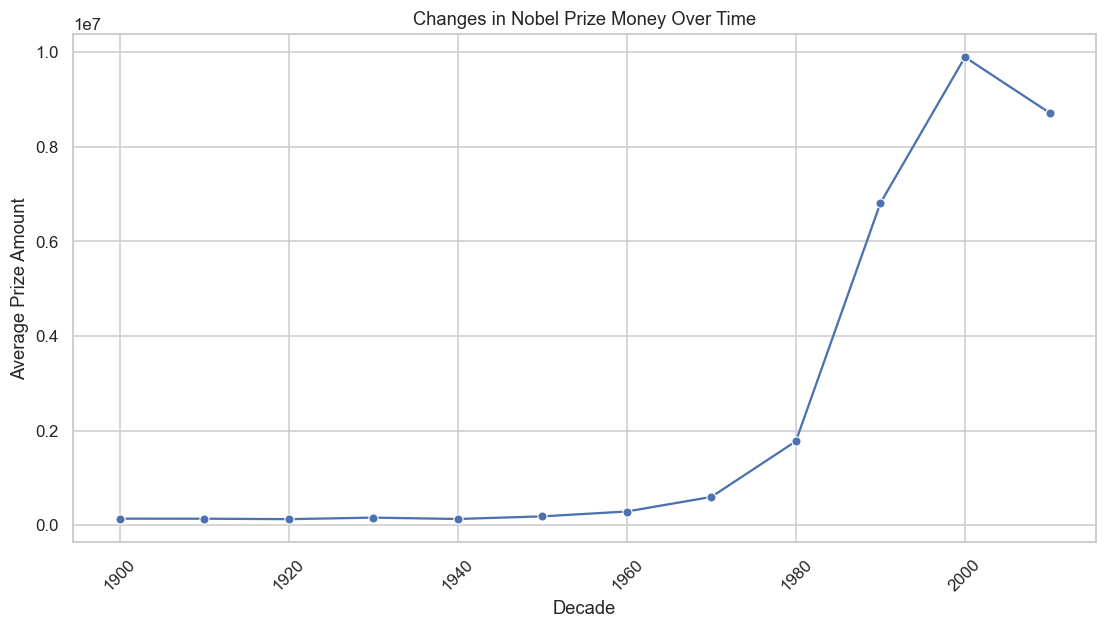

In [ ]:

prize_by_decade = (
    df.groupby("decade")["prizeAmount"]
      .mean()
)

print("Average Prize Amount by Decade:")
print(prize_by_decade)


plt.figure(figsize=(12, 6))

sns.lineplot(
    x=prize_by_decade.index,
    y=prize_by_decade.values,
    marker="o"
)

plt.xlabel("Decade")
plt.ylabel("Average Prize Amount")
plt.title("Changes in Nobel Prize Money Over Time")
plt.xticks(rotation=45)

plt.show()

Finding

 The average Nobel Prize amount increased substantially over the decades, rising from approximately 141,000 in the 1900s to 9.89 million in the 2000s. However, it decreased slightly to 8.72 million in the 2010s.

Interpretation

The Nobel Prize became financially much larger over time, although the decrease in the 2010s shows that the prize amount did not increase continuously every decade.

### Insight 12 — Academic Powerhouses

***Question:*** Which institutions appear most frequently in affiliation_1 through affiliation_4 across scientific disciplines?

***Analysis:*** Combine the four affiliation columns, count how frequently each institution appears, and identify the institutions with the highest number of Nobel laureate affiliations.

Top 10 Academic Institutions:
Harvard University, Cambridge, MA, USA                             27
Massachusetts Institute of Technology (MIT), Cambridge, MA, USA    21
California Institute of Technology (Caltech), Pasadena, CA, USA    19
Stanford University, Stanford, CA, USA                             18
University of California, Berkeley, CA, USA                        18
University of Chicago, Chicago, IL, USA                            18
University of Cambridge, Cambridge, United Kingdom                 18
Columbia University, New York, NY, USA                             16
Princeton University, Princeton, NJ, USA                           15
Rockefeller University, New York, NY, USA                          12
Name: count, dtype: int64


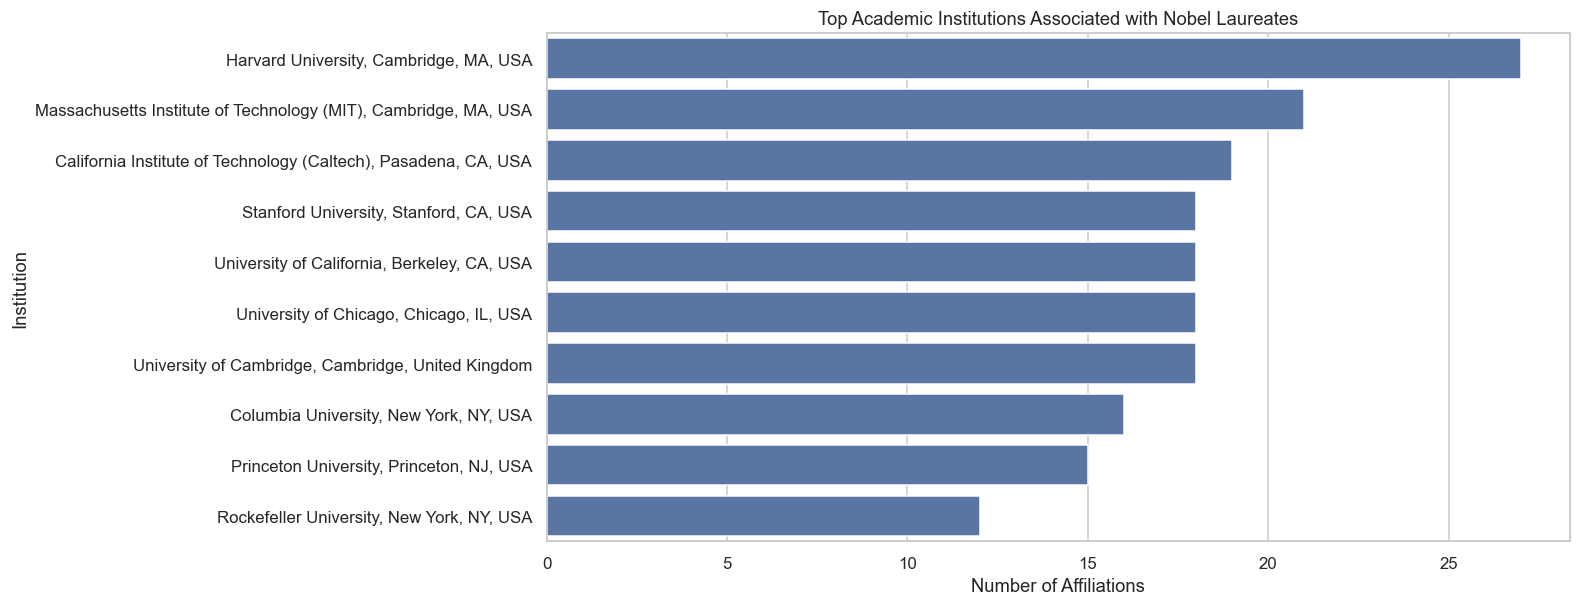

In [ ]:

scientific = df[
    df["category"].isin([
        "Physics",
        "Chemistry",
        "Physiology or Medicine",
        "Economic Sciences"
    ])
].copy()


affiliations = pd.concat([
    scientific["affiliation_1"],
    scientific["affiliation_2"],
    scientific["affiliation_3"],
    scientific["affiliation_4"]
])


affiliations = affiliations.dropna()


institution_counts = affiliations.value_counts()

print("Top 10 Academic Institutions:")
print(institution_counts.head(10))

top_institutions = institution_counts.head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_institutions.values,
    y=top_institutions.index
)

plt.xlabel("Number of Affiliations")
plt.ylabel("Institution")
plt.title("Top Academic Institutions Associated with Nobel Laureates")

plt.show()

Finding

Harvard University appears most frequently, with 27 affiliations, followed by MIT (21) and Caltech (19). Stanford, UC Berkeley, University of Chicago, and University of Cambridge each appear 18 times.

Interpretation

The results show that a relatively small group of prestigious research institutions appears repeatedly among Nobel laureates in scientific disciplines, highlighting their strong presence in Nobel-level research and academic achievement.

### ***KEY FINDINGS***


1. 🏆 **Age has no single “perfect” time for a Nobel.** Physics laureates have the youngest typical age (**56**), while Literature and Economics have the oldest (**67**). The extremes range from **Malala Yousafzai at 17** to **John B. Goodenough at 97**.

2. 🌍 **The Nobel map keeps expanding.** New countries continued to appear over time, showing that Nobel recognition has gradually become more **globally diverse**.

3. 🕊️ **The Peace Prize stands apart.** It is the only category that includes **organizations**, with **27 organizations** alongside 107 individuals.

4. 💰 **The prize became dramatically more valuable.** The average amount grew from about **141,000** in the 1900s to **9.89 million** in the 2000s, before a slight decline in the 2010s.

5. ⏳ **Four laureates created unusual timing cases.** They died in the same year they received their prizes, showing why **year-level data alone cannot determine whether an award was truly posthumous**.



### **What Surprised Me the Most ?**

What surprised me the most was how dramatically the **average Nobel Prize amount increased over time**. It rose from about **141,000** in the 1900s to **9.89 million** in the 2000s. I expected the prize to increase gradually, but the scale of the increase was much larger than I anticipated.


### **What Additional Analysis Would You Perform If You Had More Information or Additional Data?**

I would investigate why certain universities, such as**Harvard, MIT, and Caltech**, appear so frequently among Nobel laureates. With additional data about **education, research institutions, and career history**, I could analyze whether attending or working at certain institutions is associated with a higher likelihood of Nobel recognition.
